In [2]:
!wget https://github.com/garythung/trashnet/raw/master/data/dataset-resized.zip

--2026-11-23 15:53:38--  https://github.com/garythung/trashnet/raw/master/data/dataset-resized.zip
Resolving github.com (github.com)... 140.82.113.3
Connecting to github.com (github.com)|140.82.113.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/garythung/trashnet/master/data/dataset-resized.zip [following]
--2026-11-23 15:53:38--  https://raw.githubusercontent.com/garythung/trashnet/master/data/dataset-resized.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 42834870 (41M) [application/zip]
Saving to: ‘dataset-resized.zip’

dataset-resized.zip 100%[===================>]  40.85M   196MB/s    in 0.2s    

2026-11-23 15:53:39 (196 MB/s) - ‘dataset-resized.zip’ saved [42834870/42834870]



In [3]:
!unzip -q dataset-resized.zip -d waste_dataset

In [4]:
import zipfile
import os

zip_path = "dataset-resized.zip"
extract_path = "waste_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path))

Dataset extracted successfully!
['__MACOSX', 'dataset-resized']


In [5]:
import os

dataset_path = "waste_dataset/dataset-resized"

categories = ["cardboard", "glass", "metal", "paper", "plastic"]

for category in categories:
    folder_path = os.path.join(dataset_path, category)
    image_count = len(os.listdir(folder_path))
    print(f"{category}: {image_count} images")

cardboard: 403 images
glass: 501 images
metal: 410 images
paper: 594 images
plastic: 482 images


In [6]:
!pip install split-folders

In [7]:
import splitfolders

splitfolders.ratio(
    "waste_dataset/dataset-resized",
    output="waste_split",
    seed=42,
    ratio=(0.70, 0.15, 0.15),
    group_prefix=None
)

Copying files: 2527 files [00:00, 3937.99 files/s]


In [8]:
import os

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")

    split_path = f"waste_split/{split}"

    for category in sorted(os.listdir(split_path)):
        count = len(os.listdir(os.path.join(split_path, category)))
        print(f"{category}: {count}")


TRAIN
cardboard: 282
glass: 350
metal: 287
paper: 415
plastic: 337
trash: 95

VAL
cardboard: 60
glass: 75
metal: 61
paper: 89
plastic: 72
trash: 20

TEST
cardboard: 61
glass: 76
metal: 62
paper: 90
plastic: 73
trash: 22


In [9]:
import os
import shutil

source_path = "waste_dataset/dataset-resized"
filtered_path = "waste_5class"

categories = ["cardboard", "glass", "metal", "paper", "plastic"]

os.makedirs(filtered_path, exist_ok=True)

for category in categories:
    shutil.copytree(
        os.path.join(source_path, category),
        os.path.join(filtered_path, category),
        dirs_exist_ok=True
    )

print("Five-class dataset created successfully!")
print("Categories:", os.listdir(filtered_path))

Five-class dataset created successfully!
Categories: ['glass', 'plastic', 'metal', 'cardboard', 'paper']


In [10]:
import splitfolders

splitfolders.ratio(
    "waste_5class",
    output="waste_5class_split",
    seed=42,
    ratio=(0.70, 0.15, 0.15)
)

print("Five-class dataset split completed!")

Copying files: 2390 files [00:00, 6958.06 files/s]

Five-class dataset split completed!


In [11]:
import os

base_path = "waste_5class_split"

total = 0

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")
    split_total = 0

    for category in sorted(os.listdir(os.path.join(base_path, split))):
        folder = os.path.join(base_path, split, category)
        count = len([
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        print(f"{category}: {count}")
        split_total += count

    print("Total:", split_total)
    total += split_total

print("\nOverall dataset total:", total)


TRAIN
cardboard: 282
glass: 350
metal: 287
paper: 415
plastic: 337
Total: 1671

VAL
cardboard: 60
glass: 75
metal: 61
paper: 89
plastic: 72
Total: 357

TEST
cardboard: 61
glass: 76
metal: 62
paper: 90
plastic: 73
Total: 362

Overall dataset total: 2390


In [12]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

train_dataset = datasets.ImageFolder(
    "waste_5class_split/train",
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    "waste_5class_split/val",
    transform=test_transform
)

test_dataset = datasets.ImageFolder(
    "waste_5class_split/test",
    transform=test_transform
)

print("Classes:", train_dataset.classes)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic']
Training images: 1671
Validation images: 357
Testing images: 362


In [13]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 53
Validation batches: 12
Testing batches: 12


In [14]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10].tolist())
print("Class names:", train_dataset.classes)

Image batch shape: torch.Size([32, 3, 128, 128])
Label batch shape: torch.Size([32])
First 10 labels: [2, 1, 4, 0, 4, 0, 4, 3, 2, 1]
Class names: ['cardboard', 'glass', 'metal', 'paper', 'plastic']


In [15]:
import torch
import torch.nn as nn

class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 16 * 16, 128),
            nn.ReLU(),
            nn.Linear(128, 5)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = BaselineCNN().to(device)

print("Device:", device)
print(model)

Device: cpu
BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=16384, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=5, bias=True)
  )
)


In [16]:
import torch
import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 10

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(epochs):

    # Training
    model.train()
    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct / total

    # Validation
    model.eval()
    val_running_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()
            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_acc = 100 * val_correct / val_total

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc:.2f}%"
    )

Epoch [1/10] | Train Loss: 1.3434 | Train Acc: 42.43% | Val Loss: 1.1644 | Val Acc: 52.38%
Epoch [2/10] | Train Loss: 1.0971 | Train Acc: 56.85% | Val Loss: 1.0586 | Val Acc: 58.54%
Epoch [3/10] | Train Loss: 0.9995 | Train Acc: 61.76% | Val Loss: 1.0078 | Val Acc: 60.50%
Epoch [4/10] | Train Loss: 0.8871 | Train Acc: 66.01% | Val Loss: 1.2403 | Val Acc: 54.62%
Epoch [5/10] | Train Loss: 0.8802 | Train Acc: 67.38% | Val Loss: 0.9573 | Val Acc: 63.59%
Epoch [6/10] | Train Loss: 0.7955 | Train Acc: 69.84% | Val Loss: 0.9593 | Val Acc: 64.99%
Epoch [7/10] | Train Loss: 0.7361 | Train Acc: 72.17% | Val Loss: 0.9247 | Val Acc: 64.71%
Epoch [8/10] | Train Loss: 0.6898 | Train Acc: 75.52% | Val Loss: 0.9733 | Val Acc: 65.55%
Epoch [9/10] | Train Loss: 0.6271 | Train Acc: 76.54% | Val Loss: 0.8167 | Val Acc: 70.03%
Epoch [10/10] | Train Loss: 0.5711 | Train Acc: 78.28% | Val Loss: 0.8180 | Val Acc: 70.59%


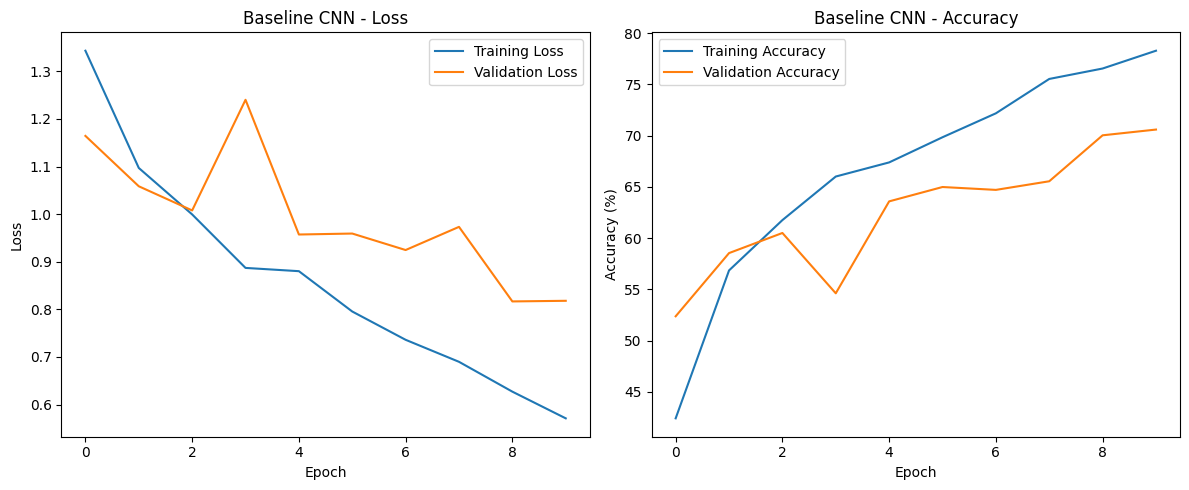

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Loss graph
plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.title("Baseline CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

# Accuracy graph
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")
plt.title("Baseline CNN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()

plt.tight_layout()
plt.show()

In [18]:
model.eval()

correct = 0
total = 0
test_loss = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total
test_loss = test_loss / len(test_loader)

print(f"Baseline Test Accuracy: {test_accuracy:.2f}%")
print(f"Baseline Test Loss: {test_loss:.4f}")

Baseline Test Accuracy: 68.51%
Baseline Test Loss: 0.8335


In [19]:
class ImprovedCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(128, 5)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x


improved_model = ImprovedCNN().to(device)

print("Improved CNN created successfully!")
print("Device:", device)
print(improved_model)

Improved CNN created successfully!
Device: cpu
ImprovedCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (classifier): Sequential(
    (0

In [20]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    improved_model.parameters(),
    lr=0.001
)

epochs = 10

improved_train_losses = []
improved_val_losses = []
improved_train_accuracies = []
improved_val_accuracies = []

for epoch in range(epochs):

    # Training
    improved_model.train()
    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = improved_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct / total

    # Validation
    improved_model.eval()
    val_running_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = improved_model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_acc = 100 * val_correct / val_total

    improved_train_losses.append(train_loss)
    improved_val_losses.append(val_loss)
    improved_train_accuracies.append(train_acc)
    improved_val_accuracies.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc:.2f}%"
    )

Epoch [1/10] | Train Loss: 1.3114 | Train Acc: 46.50% | Val Loss: 1.2013 | Val Acc: 47.90%
Epoch [2/10] | Train Loss: 1.1334 | Train Acc: 56.25% | Val Loss: 0.9946 | Val Acc: 56.30%
Epoch [3/10] | Train Loss: 1.0606 | Train Acc: 60.74% | Val Loss: 1.0379 | Val Acc: 57.70%
Epoch [4/10] | Train Loss: 1.0264 | Train Acc: 61.28% | Val Loss: 1.0488 | Val Acc: 56.30%
Epoch [5/10] | Train Loss: 0.9750 | Train Acc: 63.26% | Val Loss: 0.9255 | Val Acc: 63.31%
Epoch [6/10] | Train Loss: 0.9580 | Train Acc: 64.15% | Val Loss: 0.9965 | Val Acc: 61.62%
Epoch [7/10] | Train Loss: 0.9581 | Train Acc: 63.14% | Val Loss: 0.9220 | Val Acc: 61.90%
Epoch [8/10] | Train Loss: 0.9658 | Train Acc: 62.36% | Val Loss: 0.9995 | Val Acc: 61.62%
Epoch [9/10] | Train Loss: 0.9374 | Train Acc: 64.33% | Val Loss: 0.8804 | Val Acc: 63.03%
Epoch [10/10] | Train Loss: 0.9040 | Train Acc: 65.47% | Val Loss: 0.8921 | Val Acc: 61.34%


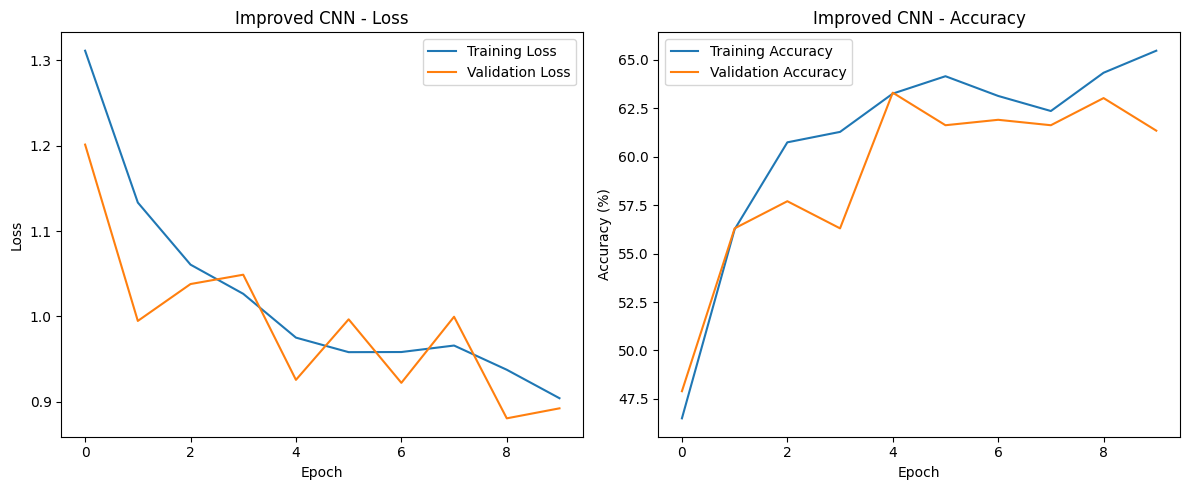

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(improved_train_losses, label="Training Loss")
plt.plot(improved_val_losses, label="Validation Loss")
plt.title("Improved CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(improved_train_accuracies, label="Training Accuracy")
plt.plot(improved_val_accuracies, label="Validation Accuracy")
plt.title("Improved CNN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()

plt.tight_layout()
plt.show()

In [22]:
improved_model.eval()

correct = 0
total = 0
test_loss = 0

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = improved_model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

improved_test_accuracy = 100 * correct / total
improved_test_loss = test_loss / len(test_loader)

print(f"Improved CNN Test Accuracy: {improved_test_accuracy:.2f}%")
print(f"Improved CNN Test Loss: {improved_test_loss:.4f}")

Improved CNN Test Accuracy: 61.05%
Improved CNN Test Loss: 0.9488



Baseline CNN Classification Report
              precision    recall  f1-score   support

   cardboard       0.65      0.84      0.73        61
       glass       0.69      0.57      0.62        76
       metal       0.64      0.68      0.66        62
       paper       0.76      0.80      0.78        90
     plastic       0.67      0.55      0.60        73

    accuracy                           0.69       362
   macro avg       0.68      0.69      0.68       362
weighted avg       0.69      0.69      0.68       362



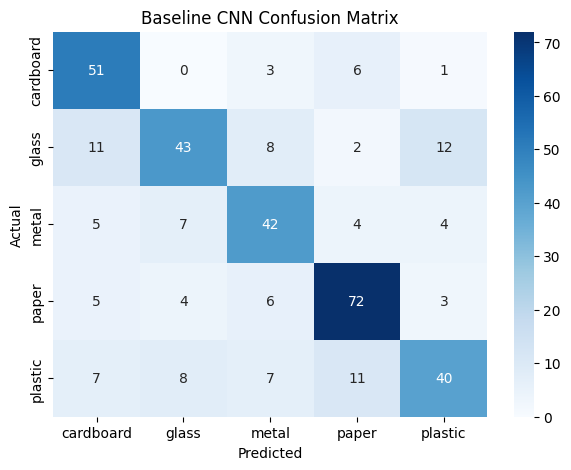


Improved CNN Classification Report
              precision    recall  f1-score   support

   cardboard       0.79      0.79      0.79        61
       glass       0.46      0.78      0.58        76
       metal       0.79      0.31      0.44        62
       paper       0.77      0.56      0.65        90
     plastic       0.54      0.62      0.57        73

    accuracy                           0.61       362
   macro avg       0.67      0.61      0.61       362
weighted avg       0.66      0.61      0.61       362



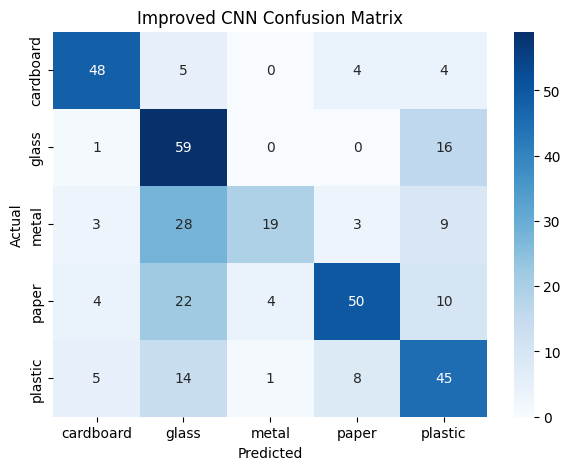

In [23]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

def evaluate_model(model, model_name):

    model.eval()
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)

            outputs = model(images)
            predictions = torch.argmax(outputs, dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.numpy())

    print(f"\n{model_name} Classification Report")

    print(classification_report(
        all_labels,
        all_predictions,
        target_names=train_dataset.classes
    ))

    cm = confusion_matrix(all_labels, all_predictions)

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=train_dataset.classes,
        yticklabels=train_dataset.classes,
        cmap="Blues"
    )

    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


evaluate_model(model, "Baseline CNN")
evaluate_model(improved_model, "Improved CNN")

In [24]:
from sklearn.metrics import classification_report

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(
    all_labels,
    all_predictions,
    target_names=train_dataset.classes,
    digits=4
))

              precision    recall  f1-score   support

   cardboard     0.6456    0.8361    0.7286        61
       glass     0.6935    0.5658    0.6232        76
       metal     0.6364    0.6774    0.6562        62
       paper     0.7579    0.8000    0.7784        90
     plastic     0.6667    0.5479    0.6015        73

    accuracy                         0.6851       362
   macro avg     0.6800    0.6854    0.6776       362
weighted avg     0.6862    0.6851    0.6808       362



In [25]:
torch.save(model.state_dict(), "baseline_cnn.pth")

torch.save(
    improved_model.state_dict(),
    "improved_cnn.pth"
)

print("Both models saved successfully!")

Both models saved successfully!


Total incorrect predictions: 114


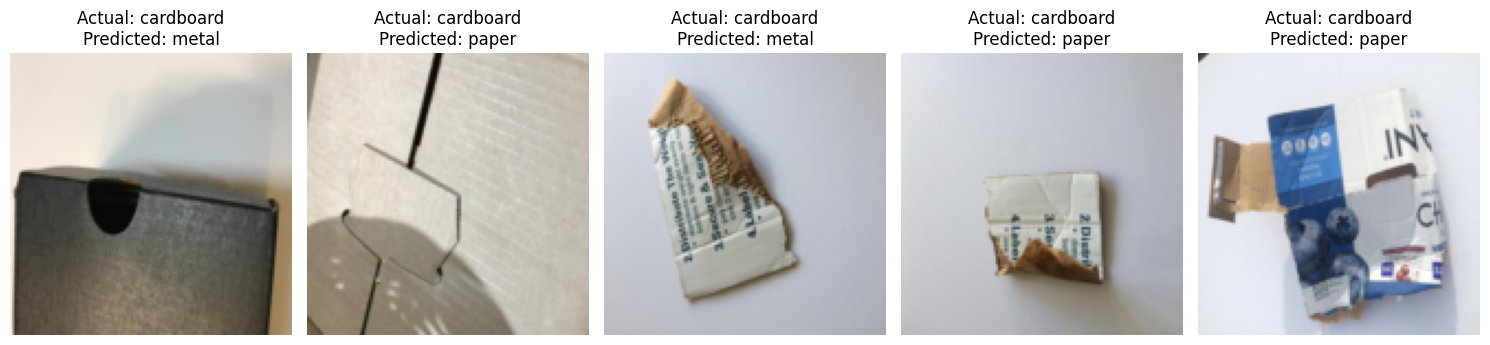

In [26]:
import matplotlib.pyplot as plt

model.eval()

wrong_images = []
wrong_labels = []
wrong_predictions = []

with torch.no_grad():
    for images, labels in test_loader:

        outputs = model(images.to(device))
        predictions = torch.argmax(outputs, dim=1).cpu()

        for i in range(len(labels)):
            if predictions[i] != labels[i]:
                wrong_images.append(images[i])
                wrong_labels.append(labels[i].item())
                wrong_predictions.append(predictions[i].item())

print("Total incorrect predictions:", len(wrong_images))

# Display first 5 incorrect predictions
plt.figure(figsize=(15, 5))

for i in range(min(5, len(wrong_images))):
    image = wrong_images[i].permute(1, 2, 0)
    image = image * 0.5 + 0.5

    plt.subplot(1, 5, i + 1)
    plt.imshow(image.clamp(0, 1))
    plt.title(
        f"Actual: {train_dataset.classes[wrong_labels[i]]}\n"
        f"Predicted: {train_dataset.classes[wrong_predictions[i]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [27]:
from sklearn.metrics import confusion_matrix
import pandas as pd

cm = confusion_matrix(all_labels, all_predictions)

confusion_df = pd.DataFrame(
    cm,
    index=train_dataset.classes,
    columns=train_dataset.classes
)

print("Baseline CNN Confusion Matrix:")
display(confusion_df)

Baseline CNN Confusion Matrix:


,cardboard,glass,metal,paper,plastic
cardboard,51,0,3,6,1
glass,11,43,8,2,12
metal,5,7,42,4,4
paper,5,4,6,72,3
plastic,7,8,7,11,40


In [28]:
import os
import hashlib
from collections import defaultdict

base_path = "waste_5class_split"

image_hashes = defaultdict(list)

for split in ["train", "val", "test"]:
    for category in os.listdir(os.path.join(base_path, split)):
        folder = os.path.join(base_path, split, category)

        for filename in os.listdir(folder):
            path = os.path.join(folder, filename)

            with open(path, "rb") as f:
                file_hash = hashlib.md5(f.read()).hexdigest()

            image_hashes[file_hash].append((split, category, filename))

duplicates = []

for file_hash, locations in image_hashes.items():
    splits = set(item[0] for item in locations)

    if len(splits) > 1:
        duplicates.append(locations)

print("Duplicate groups across splits:", len(duplicates))

Duplicate groups across splits: 1


In [29]:
for locations in duplicates:
    print("\nDuplicate image found:")
    for split, category, filename in locations:
        print(f"Split: {split} | Category: {category} | File: {filename}")


Duplicate image found:
Split: train | Category: plastic | File: plastic332.jpg
Split: test | Category: glass | File: glass389.jpg


In [30]:
import os

duplicate_path = "waste_5class_split/test/glass/glass389.jpg"

if os.path.exists(duplicate_path):
    os.remove(duplicate_path)
    print("Duplicate test image removed successfully!")
else:
    print("File not found!")

Duplicate test image removed successfully!


In [31]:
test_dataset = datasets.ImageFolder(
    "waste_5class_split/test",
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("Updated test images:", len(test_dataset))
print("Classes:", test_dataset.classes)

Updated test images: 361
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic']


In [32]:
def test_evaluation(model, model_name):
    model.eval()
    correct = 0
    total = 0
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    accuracy = 100 * correct / total

    print(f"{model_name} Test Accuracy: {accuracy:.2f}%")
    print(f"Correct predictions: {correct}/{total}")

    return accuracy, all_labels, all_predictions


baseline_accuracy, baseline_labels, baseline_predictions = test_evaluation(
    model, "Baseline CNN"
)

improved_accuracy, improved_labels, improved_predictions = test_evaluation(
    improved_model, "Improved CNN"
)

Baseline CNN Test Accuracy: 68.70%
Correct predictions: 248/361
Improved CNN Test Accuracy: 61.22%
Correct predictions: 221/361


In [34]:
from sklearn.metrics import classification_report

print("BASELINE CNN REPORT")
print(classification_report(
    baseline_labels,
    baseline_predictions,
    target_names=test_dataset.classes
))

print("IMPROVED CNN REPORT")
print(classification_report(
    improved_labels,
    improved_predictions,
    target_names=test_dataset.classes
))

BASELINE CNN REPORT
              precision    recall  f1-score   support

   cardboard       0.65      0.84      0.73        61
       glass       0.69      0.57      0.63        75
       metal       0.64      0.68      0.66        62
       paper       0.76      0.80      0.78        90
     plastic       0.68      0.55      0.61        73

    accuracy                           0.69       361
   macro avg       0.68      0.69      0.68       361
weighted avg       0.69      0.69      0.68       361

IMPROVED CNN REPORT
              precision    recall  f1-score   support

   cardboard       0.79      0.79      0.79        61
       glass       0.46      0.79      0.58        75
       metal       0.79      0.31      0.44        62
       paper       0.77      0.56      0.65        90
     plastic       0.54      0.62      0.58        73

    accuracy                           0.61       361
   macro avg       0.67      0.61      0.61       361
weighted avg       0.67      0.61    

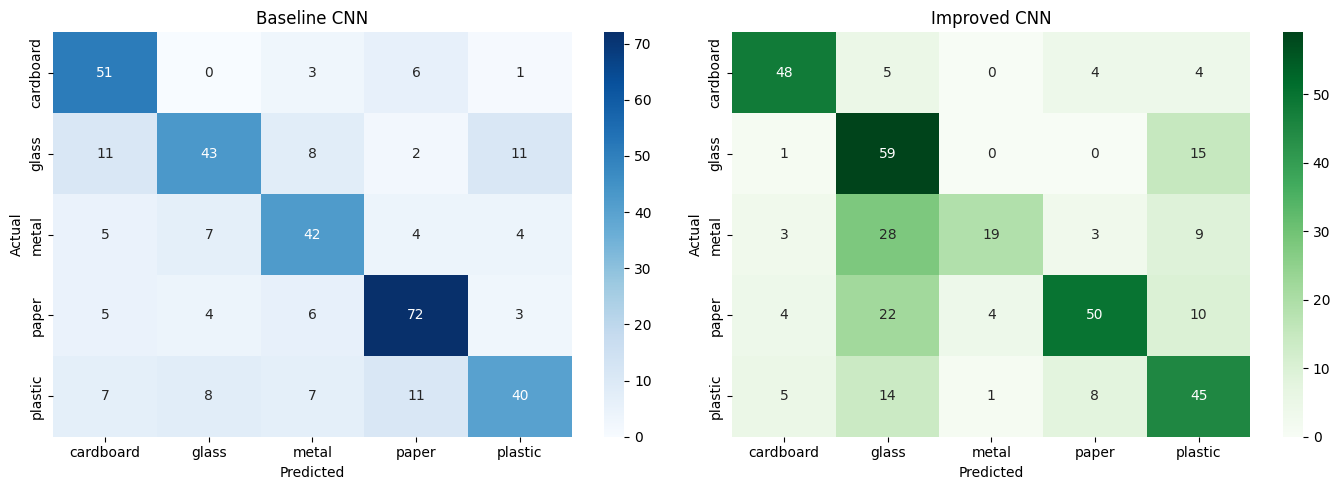

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Baseline CNN
cm_baseline = confusion_matrix(
    baseline_labels, baseline_predictions
)

sns.heatmap(
    cm_baseline,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=test_dataset.classes,
    yticklabels=test_dataset.classes,
    ax=axes[0]
)

axes[0].set_title("Baseline CNN")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Improved CNN
cm_improved = confusion_matrix(
    improved_labels, improved_predictions
)

sns.heatmap(
    cm_improved,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=test_dataset.classes,
    yticklabels=test_dataset.classes,
    ax=axes[1]
)

axes[1].set_title("Improved CNN")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

Baseline CNN: 113 incorrect predictions


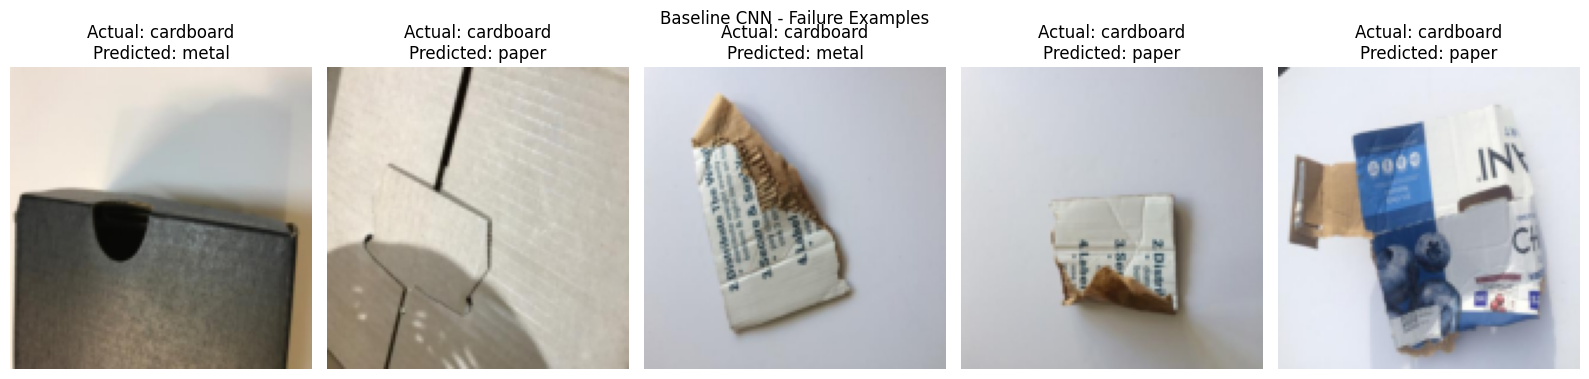

Improved CNN: 140 incorrect predictions


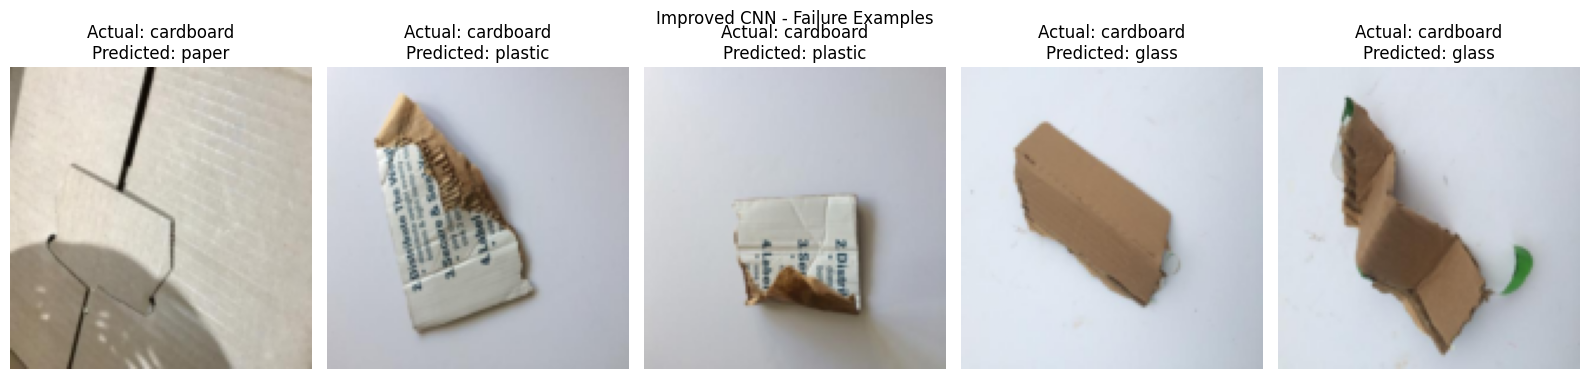

In [37]:
import matplotlib.pyplot as plt
import torch

class_names = test_dataset.classes

def show_mistakes(labels, predictions, model_name):
    wrong_indices = [
        i for i in range(len(labels))
        if labels[i] != predictions[i]
    ]

    print(f"{model_name}: {len(wrong_indices)} incorrect predictions")

    fig, axes = plt.subplots(1, 5, figsize=(16, 4))

    for ax, idx in zip(axes, wrong_indices[:5]):
        image, actual = test_dataset[idx]

        # Reverse normalization
        image = image * 0.5 + 0.5
        image = image.permute(1, 2, 0).numpy()

        ax.imshow(image)
        ax.set_title(
            f"Actual: {class_names[actual]}\n"
            f"Predicted: {class_names[predictions[idx]]}"
        )
        ax.axis("off")

    plt.suptitle(f"{model_name} - Failure Examples")
    plt.tight_layout()
    plt.show()


show_mistakes(
    baseline_labels,
    baseline_predictions,
    "Baseline CNN"
)

show_mistakes(
    improved_labels,
    improved_predictions,
    "Improved CNN"
)

### Failure Analysis

Both CNN models produced incorrect predictions on some test images.

**Baseline CNN:**
- Incorrect predictions: 113 out of 361 images.
- Some cardboard images were incorrectly classified as metal or paper.
- The model achieved better overall accuracy than the improved CNN.

**Improved CNN:**
- Incorrect predictions: 140 out of 361 images.
- Some cardboard images were classified as paper, plastic and glass.
- The model frequently confused metal with glass.

**Possible reasons for incorrect predictions:**
1. Similar visual appearance between different waste categories.
2. Limited number of training images.
3. Variations in image lighting, background and orientation.
4. Some waste materials have overlapping visual features.

### Suggested Improvements

The model performance could be improved through the following approaches:

1. Collect more images for each waste category.
2. Apply data augmentation such as rotation, flipping and zooming.
3. Experiment with different learning rates and batch sizes.
4. Train the models for more epochs with early stopping.
5. Use transfer learning with pretrained models such as ResNet18 or MobileNetV2.
6. Improve image quality and remove incorrectly labelled images.

These improvements may help the model recognize waste categories more accurately.